# The expectations inside the DKF ELBO: hierarchical, not nested

The Deep Kalman Filter paper (Krishnan, Shalit & Sontag, 2015) writes its lower bound as

$$
\mathcal{L}(\mathbf{x})
= \sum_{t=1}^{T} \mathbb{E}_{q(z_t \mid \mathbf{x})}\big[\log p(x_t \mid z_t)\big]
\;-\; \mathrm{KL}\big(q(z_1 \mid \mathbf{x}) \,\|\, p(z_1)\big)
\;-\; \sum_{t=2}^{T} \mathbb{E}_{q(z_{t-1} \mid \mathbf{x})}\Big[\mathrm{KL}\big(q(z_t \mid z_{t-1}, \mathbf{x}) \,\|\, p(z_t \mid z_{t-1})\big)\Big].
$$

It then moves on without explaining three things that tend to puzzle readers:

1. **Where does this form come from?** In particular, why does each KL term sit inside an expectation over
   $q(z_{t-1}\mid\mathbf{x})$?
2. **How can we compute $\mathbb{E}_{q(z_{t-1}\mid \mathbf{x})}[\cdot]$?** That marginal is intractable as
   soon as the encoder is a neural network. Does it take an outer loop over $z_{t-1}$ and an inner loop over $z_t$,
   i.e. *nested* Monte Carlo?
3. **Why bother with the factorised form?** The paper only remarks that sampling the KL term gives
   high-variance gradients, and that the factorisation helps.

This notebook answers all three, using one unifying idea: the difference between **hierarchical** and
**nested** Monte Carlo. The short answers are:

1. The factorisation is the *chain rule for KL divergence*, together with the fact that each term depends only
   on two consecutive time steps.
2. Every expectation in the ELBO is **linear** in what it averages, so it is *hierarchical* Monte Carlo, not
   nested. A **single ancestral trajectory** $z_{1:T} \sim q(z_{1:T}\mid\mathbf{x})$ gives an unbiased estimate
   of the whole bound. No marginal ever has to be computed.
3. Computing each KL term in closed form, given the sampled $z_{t-1}$, **integrates out** $z_t$ analytically.
   That is Rao–Blackwellisation. As section 5 shows, it lowers the variance of each KL term but not necessarily of
   the whole ELBO. Here it did lower the variance of the training gradients, moderately.

Nested Monte Carlo *does* appear in this story, but somewhere else: in the log-likelihood
$\log p(\mathbf{x})$ that the ELBO bounds, and in importance-weighted (IWAE) estimates of it. Section 8 shows this.

Everything is checked numerically on a linear-Gaussian state-space model, where the ELBO, the posterior and
$\log p(\mathbf{x})$ are all available in closed form.

*Background:* the two notions are developed from scratch in the companion repository
[Nested-Monte-Carlo-sampling](https://github.com/CL-BZH/Nested-Monte-Carlo-sampling), in Part 1 (hierarchical)
and Part 2 (nested).

**Contents**
1. Hierarchical vs nested Monte Carlo in one paragraph
2. Deriving the factorised ELBO
3. The marginals $q(z_t\mid\mathbf{x})$ are never needed: ancestral sampling
4. A test bed where everything is exact
5. Three unbiased estimators of the ELBO
6. Gradients: what "factorising the KL" buys during training
7. How this repository's code implements it
8. Where nesting really appears: $\log p(\mathbf{x})$ and IWAE
9. Summary

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
LOG2PI = np.log(2.0 * np.pi)
rng = np.random.default_rng(2026)

## 1. Hierarchical vs nested Monte Carlo in one paragraph

Take an expectation with two layers of randomness, $u$ outside and $v$ inside.

* **Hierarchical:** $\;\mathbb{E}_{u}\big[\mathbb{E}_{v\mid u}[h(u,v)]\big]$. The inner expectation enters
  **linearly**, so by the tower property this is just $\mathbb{E}_{(u,v)}[h(u,v)]$. Drawing $u$, then a single
  $v\mid u$, and evaluating $h$ is unbiased. Drawing several $v$'s per $u$ is allowed but never required, and if
  $\mathbb{E}_{v\mid u}[h]$ is known in closed form, using it instead of sampling $v$ reduces variance
  (**Rao–Blackwellisation**).
* **Nested:** $\;\mathbb{E}_{u}\big[f\big(\mathbb{E}_{v\mid u}[h(u,v)]\big)\big]$ with $f$ **nonlinear**, e.g.
  $f = \log$. The inner expectation must be estimated before $f$ is applied. Any finite inner sample size $M$
  creates bias of order $1/M$, and a single inner sample estimates the wrong quantity altogether.

The question for the DKF is therefore simple: **is anything nonlinear applied to an inner expectation?**

## 2. Deriving the factorised ELBO

**Model.** The generative model is a Markov chain of latents with emissions:

$$
p(\mathbf{x}, \mathbf{z}) = p(z_1)\prod_{t=2}^{T} p(z_t \mid z_{t-1}) \prod_{t=1}^{T} p(x_t \mid z_t).
$$

**Inference network.** The posterior $p(\mathbf{z}\mid\mathbf{x})$ of this model is itself Markov, and $z_t$ only
depends on the past through $z_{t-1}$. So the DKF uses an encoder of the same shape:

$$
q(\mathbf{z}\mid\mathbf{x}) = q(z_1\mid\mathbf{x}) \prod_{t=2}^{T} q(z_t \mid z_{t-1}, \mathbf{x}).
$$

In this repository $q(z_t\mid z_{t-1},\mathbf{x})$ is computed by the *combiner*, which takes the sampled $z_{t-1}$
and the backward-RNN state summarising $x_{t:T}$.

**Step 1 — the usual VAE bound.** For any $q$, Jensen's inequality gives

$$
\log p(\mathbf{x}) \;\ge\; \mathbb{E}_{q(\mathbf{z}\mid\mathbf{x})}\big[\log p(\mathbf{x}\mid\mathbf{z})\big]
- \mathrm{KL}\big(q(\mathbf{z}\mid\mathbf{x}) \,\|\, p(\mathbf{z})\big) \;=\; \mathcal{L}(\mathbf{x}),
$$

and the gap is exactly $\mathrm{KL}\big(q(\mathbf{z}\mid\mathbf{x}) \,\|\, p(\mathbf{z}\mid\mathbf{x})\big)$.

**Step 2 — reconstruction term.** Since $\log p(\mathbf{x}\mid\mathbf{z}) = \sum_t \log p(x_t \mid z_t)$ and the
$t$-th term depends on $z_t$ only, its expectation under the joint $q(z_{1:T}\mid\mathbf{x})$ equals its
expectation under the marginal $q(z_t\mid\mathbf{x})$. Integrating out a variable that a function does not depend on
just yields the marginal of the others:

$$
\mathbb{E}_{q(z_{1:T}\mid\mathbf{x})}\Big[\sum_t \log p(x_t\mid z_t)\Big] = \sum_t \mathbb{E}_{q(z_t\mid\mathbf{x})}\big[\log p(x_t\mid z_t)\big].
$$

**Step 3 — the KL term (chain rule for KL).** Write the log-ratio with both factorisations:

$$
\log\frac{q(\mathbf{z}\mid\mathbf{x})}{p(\mathbf{z})}
= \log\frac{q(z_1\mid\mathbf{x})}{p(z_1)} + \sum_{t=2}^{T} \underbrace{\log\frac{q(z_t\mid z_{t-1},\mathbf{x})}{p(z_t\mid z_{t-1})}}_{r_t(z_{t-1},\, z_t)}.
$$

Each $r_t$ depends only on the pair $(z_{t-1}, z_t)$, so as in step 2 its expectation is taken under the pair
marginal $q(z_{t-1}, z_t\mid\mathbf{x}) = q(z_{t-1}\mid\mathbf{x})\,q(z_t\mid z_{t-1},\mathbf{x})$. Splitting that
expectation with the tower property, the inner expectation is a KL divergence:

$$
\mathbb{E}_{q(z_{t-1},z_t\mid\mathbf{x})}[r_t]
= \mathbb{E}_{q(z_{t-1}\mid\mathbf{x})}\Big[\underbrace{\mathbb{E}_{q(z_t\mid z_{t-1},\mathbf{x})}[r_t]}_{=\ \mathrm{KL}(q(z_t\mid z_{t-1},\mathbf{x})\,\|\,p(z_t\mid z_{t-1}))}\Big].
$$

Summing over $t$ gives the bound displayed at the top. This answers question 1: **the expectation over
$q(z_{t-1}\mid\mathbf{x})$ is the outer half of a tower-property split, and the KL is the inner half.**

**The key structural fact.** Look at how the inner expectation enters: it is *added* to the bound. Nothing
nonlinear is applied to it. By section 1, every term of the ELBO is a **hierarchical** expectation. So we never
have to compute the inner expectation separately before using it; sampling it once is already unbiased.

## 3. The marginals $q(z_t\mid\mathbf{x})$ are never needed: ancestral sampling

With a neural encoder, $q(z_t\mid z_{t-1},\mathbf{x})$ is Gaussian, but the marginal
$q(z_t\mid\mathbf{x}) = \int q(z_t\mid z_{t-1},\mathbf{x})\, q(z_{t-1}\mid\mathbf{x})\,dz_{t-1}$ is an intractable
integral over all earlier latents. So how can we take expectations under it?

**We don't need its density, only samples from it.** Draw one trajectory by *ancestral sampling*:

$$
z_1 \sim q(z_1\mid\mathbf{x}),\quad z_2 \sim q(z_2\mid z_1,\mathbf{x}),\quad \dots,\quad z_T \sim q(z_T\mid z_{T-1},\mathbf{x}).
$$

The trajectory is an exact draw from the joint $q(z_{1:T}\mid\mathbf{x})$, so **each** $z_t$ is an exact draw from
its marginal $q(z_t\mid\mathbf{x})$, and each pair $(z_{t-1}, z_t)$ is an exact draw from the pair marginal. One
trajectory feeds every term of the ELBO at once.

A small illustration with a nonlinear encoder,
$q(z_t\mid z_{t-1}) = \mathcal{N}\big(2\tanh(2z_{t-1}),\ 0.5^2\big)$: every conditional is Gaussian, yet the marginals
quickly become bimodal and have no closed form. Ancestral sampling handles them with no extra effort.

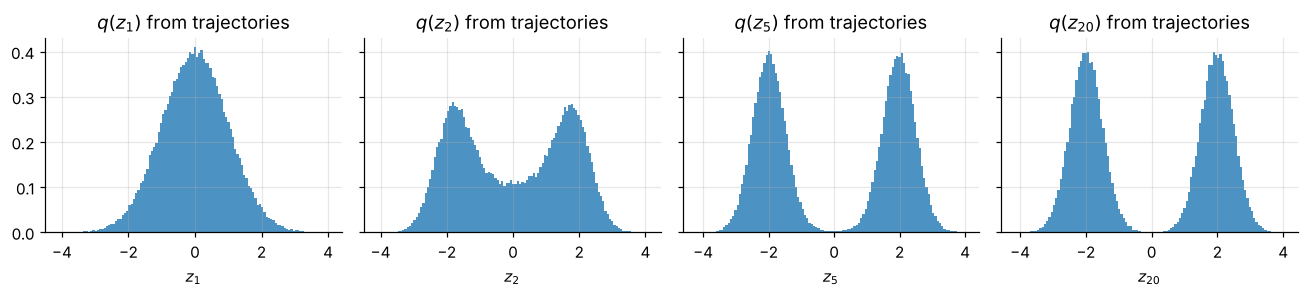

In [2]:
n_traj, T_demo = 100_000, 20
z = np.empty((n_traj, T_demo))
z[:, 0] = rng.standard_normal(n_traj)
for t in range(1, T_demo):
    z[:, t] = 2 * np.tanh(2 * z[:, t - 1]) + 0.5 * rng.standard_normal(n_traj)

fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, t in zip(axes, (0, 1, 4, 19)):
    ax.hist(z[:, t], bins=120, density=True, color="C0", alpha=0.8)
    ax.set_title(f"$q(z_{{{t + 1}}})$ from trajectories")
    ax.set_xlabel(f"$z_{{{t + 1}}}$")
plt.tight_layout()
plt.show()

## 4. A test bed where everything is exact

To check estimators against ground truth, we use a **linear-Gaussian** state-space model, the setting of the
classical Kalman filter:

$$
z_1 \sim \mathcal{N}\Big(0, \tfrac{Q}{1-a^2}\Big),\qquad
z_t \mid z_{t-1} \sim \mathcal{N}(a z_{t-1},\, Q),\qquad
x_t \mid z_t \sim \mathcal{N}(z_t,\, R),
$$

with $a = 0.9$, $\sqrt Q = 0.5$, $\sqrt R = 0.5$, and $T = 25$. We simulate one sequence $\mathbf{x}$.

Here $\mathbf{z}$ and $\mathbf{x}$ are jointly Gaussian, so:
* $\log p(\mathbf{x}) = \log\mathcal{N}(\mathbf{x};\, 0,\ \Sigma_p + R\,I)$ exactly, where $\Sigma_p$ is the
  prior covariance of $\mathbf{z}$.
* The posterior $p(\mathbf{z}\mid\mathbf{x}) = \mathcal{N}(\mu^\ast, \Sigma^\ast)$ with
  $\Sigma^\ast = (\Sigma_p^{-1} + I/R)^{-1}$ and $\mu^\ast = \Sigma^\ast\mathbf{x}/R$.

**The encoder.** We use a Markov Gaussian $q$ with the same structure as the DKF encoder:

$$
q(z_1\mid\mathbf{x}) = \mathcal{N}(\beta_1, \gamma_1^2),\qquad
q(z_t\mid z_{t-1},\mathbf{x}) = \mathcal{N}(\alpha_t z_{t-1} + \beta_t,\ \gamma_t^2).
$$

The exact posterior has this form, because Gaussian Markov chains condition into Gaussian Markov chains. Its
coefficients follow from the posterior covariance:
$\alpha_t = \Sigma^\ast_{t,t-1}/\Sigma^\ast_{t-1,t-1}$, $\beta_t = \mu^\ast_t - \alpha_t\mu^\ast_{t-1}$,
$\gamma_t^2 = \Sigma^\ast_{t,t} - \alpha_t\Sigma^\ast_{t,t-1}$.

A trained encoder is never perfect. To mimic that, we perturb the exact coefficients: every standard deviation is
multiplied by $e^{s}$ and every mean is shifted by $\delta$, with $s = 0.15$ and $\delta = 0.1$. Because $q$ is a
linear-Gaussian chain, it is a Gaussian $\mathcal{N}(m, S)$ over $\mathbf{z}$ too, so its ELBO has a closed form:

$$
\mathcal{L} = \mathbb{E}_q[\log p(\mathbf{z})] + \mathbb{E}_q[\log p(\mathbf{x}\mid\mathbf{z})] + \mathbb{H}[q].
$$

In [3]:
# ----- generative model -----
T, a, Q, R = 25, 0.9, 0.5**2, 0.5**2
P0 = Q / (1 - a**2)                                   # stationary variance of z_1
idx = np.arange(T)
Sigma_p = P0 * a ** np.abs(idx[:, None] - idx[None, :])  # prior covariance of z_{1:T}

data_rng = np.random.default_rng(7)
z_true = np.linalg.cholesky(Sigma_p) @ data_rng.standard_normal(T)
x = z_true + np.sqrt(R) * data_rng.standard_normal(T)


def log_normal_pdf(v, mean, cov):
    d = v - mean
    return -0.5 * (len(v) * LOG2PI + np.linalg.slogdet(cov)[1] + d @ np.linalg.solve(cov, d))


log_px = log_normal_pdf(x, np.zeros(T), Sigma_p + R * np.eye(T))
Sigma_post = np.linalg.inv(np.linalg.inv(Sigma_p) + np.eye(T) / R)
mu_post = Sigma_post @ x / R


# ----- Markov Gaussian encoder -----
def markov_coefficients(m, S):
    """alpha_t, beta_t, gamma_t of the Markov factorisation of N(m, S) (S with Markov structure)."""
    alpha, beta, gamma2 = np.zeros(T), np.zeros(T), np.zeros(T)
    beta[0], gamma2[0] = m[0], S[0, 0]
    for t in range(1, T):
        alpha[t] = S[t, t - 1] / S[t - 1, t - 1]
        beta[t] = m[t] - alpha[t] * m[t - 1]
        gamma2[t] = S[t, t] - alpha[t] * S[t, t - 1]
    return alpha, beta, np.sqrt(gamma2)


alpha, beta_star, gamma_star = markov_coefficients(mu_post, Sigma_post)


def encoder(s, delta):
    """Perturbed encoder: stds multiplied by exp(s), means shifted by delta."""
    return alpha, beta_star + delta, gamma_star * np.exp(s)


def q_joint(alpha, beta, gamma):
    """q(z_{1:T}) = N(m, S) for the chain z_t = alpha_t z_{t-1} + beta_t + gamma_t eps_t."""
    B = np.eye(T) - np.diag(alpha[1:], -1)
    B_inv = np.linalg.inv(B)
    return B_inv @ beta, B_inv @ np.diag(gamma**2) @ B_inv.T


def exact_elbo(s, delta):
    m, S = q_joint(*encoder(s, delta))
    Sp_inv = np.linalg.inv(Sigma_p)
    e_log_pz = -0.5 * (T * LOG2PI + np.linalg.slogdet(Sigma_p)[1] + np.trace(Sp_inv @ S) + m @ Sp_inv @ m)
    e_log_px_z = -0.5 * (T * np.log(2 * np.pi * R) + ((x - m) @ (x - m) + np.trace(S)) / R)
    entropy = 0.5 * (T * (1 + LOG2PI) + np.linalg.slogdet(S)[1])
    return e_log_pz + e_log_px_z + entropy


s0, delta0 = 0.15, 0.1
elbo_true = exact_elbo(s0, delta0)
print(f"log p(x)                       = {log_px:.4f}")
print(f"ELBO with the exact posterior  = {exact_elbo(0.0, 0.0):.4f}   (equals log p(x): the bound is tight)")
print(f"ELBO with the perturbed q      = {elbo_true:.4f}")
print(f"gap = KL(q || posterior)       = {log_px - elbo_true:.4f}")

log p(x)                       = -30.1560
ELBO with the exact posterior  = -30.1560   (equals log p(x): the bound is tight)
ELBO with the perturbed q      = -31.9935
gap = KL(q || posterior)       = 1.8375


**Checking section 3.** Ancestral sampling from $q$ reproduces the exact marginals $\mathcal{N}(m_t, S_{tt})$,
even though the sampler never computes them:

In [4]:
def sample_trajectories(n, s, delta, rng, eps=None):
    """Ancestral sampling of n trajectories. Returns z (n, T) and the noise used."""
    al, be, ga = encoder(s, delta)
    if eps is None:
        eps = rng.standard_normal((n, T))
    z = np.empty_like(eps)
    z[:, 0] = be[0] + ga[0] * eps[:, 0]
    for t in range(1, T):
        z[:, t] = al[t] * z[:, t - 1] + be[t] + ga[t] * eps[:, t]
    return z, eps


z_s, _ = sample_trajectories(200_000, s0, delta0, rng)
m_q, S_q = q_joint(*encoder(s0, delta0))
print("max |sample mean - m_t|      :", np.abs(z_s.mean(0) - m_q).max().round(4))
print("max |sample var  - S_tt|     :", np.abs(z_s.var(0) - np.diag(S_q)).max().round(4))

max |sample mean - m_t|      : 0.0018
max |sample var  - S_tt|     : 0.0012


## 5. Three unbiased estimators of the ELBO

All three use **one ancestral trajectory** $z_{1:T}\sim q$ per estimate. They differ only in how they treat
the inner expectation over $z_t \mid z_{t-1}$ inside each KL term.

**(A) Fully sampled.** Evaluate the integrand of the original bound at the trajectory:

$$
\hat{\mathcal{L}}_A = \log p(\mathbf{x}, \mathbf{z}) - \log q(\mathbf{z}\mid\mathbf{x})
= \sum_t \log p(x_t\mid z_t) - \log\tfrac{q(z_1)}{p(z_1)} - \sum_{t\ge2} r_t(z_{t-1}, z_t).
$$

Each $r_t$ is estimated with a **single** draw of $z_t$, namely the trajectory's own. In the language of
section 1, this is hierarchical sampling with $M = 1$.

**(B) Analytic KL, i.e. the DKF estimator.** Keep the sampled reconstruction terms, but replace each $r_t$ by its
conditional expectation, the Gaussian KL in closed form at the sampled $z_{t-1}$:

$$
\hat{\mathcal{L}}_B = \sum_t \log p(x_t\mid z_t) - \mathrm{KL}\big(q(z_1)\,\|\,p(z_1)\big) - \sum_{t\ge2} \mathrm{KL}\big(q(z_t\mid z_{t-1})\,\|\,p(z_t\mid z_{t-1})\big)\Big|_{z_{t-1}\ \text{sampled}} .
$$

Between two univariate Gaussians,
$\mathrm{KL}\big(\mathcal{N}(\mu_q,\sigma_q^2)\,\|\,\mathcal{N}(\mu_p,\sigma_p^2)\big) = \log\frac{\sigma_p}{\sigma_q} + \frac{\sigma_q^2 + (\mu_q-\mu_p)^2}{2\sigma_p^2} - \frac12$.
This is the $M\to\infty$ limit of hierarchical sampling: the inner expectation is integrated out exactly.

**(M) In between.** Estimate each KL term with $M$ draws of $z_t\mid z_{t-1}$: the trajectory's own draw plus
$M-1$ extra ones that are used only for this term. $M=1$ is (A), and $M\to\infty$ is (B).

By the tower property, **all of them have mean exactly $\mathcal{L}$, for any $M$.** Nothing is nested.

In [5]:
def log_ratio_terms(z, al, be, ga):
    """r_t for t = 1..T at given z (n, T): log q(z_t | z_{t-1}) - log p(z_t | z_{t-1}), with t = 1 vs p(z_1)."""
    mq = np.concatenate([be[:1] * np.ones((len(z), 1)), al[1:] * z[:, :-1] + be[1:]], axis=1)
    mp = np.concatenate([np.zeros((len(z), 1)), a * z[:, :-1]], axis=1)
    vp = np.concatenate([[P0], np.full(T - 1, Q)])
    log_q = -0.5 * (LOG2PI + 2 * np.log(ga) + (z - mq) ** 2 / ga**2)
    log_p = -0.5 * (LOG2PI + np.log(vp) + (z - mp) ** 2 / vp)
    return log_q - log_p, mq, mp, vp


def analytic_kl_terms(z, al, be, ga):
    """KL(q(z_t | z_{t-1}) || p(z_t | z_{t-1})) at the sampled z_{t-1}, t = 1..T."""
    _, mq, mp, vp = log_ratio_terms(z, al, be, ga)
    return 0.5 * np.log(vp / ga**2) + (ga**2 + (mq - mp) ** 2) / (2 * vp) - 0.5


def recon_terms(z):
    return -0.5 * (LOG2PI + np.log(R) + (x - z) ** 2 / R)


def elbo_A(z, s, delta):
    al, be, ga = encoder(s, delta)
    r, *_ = log_ratio_terms(z, al, be, ga)
    return recon_terms(z).sum(1) - r.sum(1)


def elbo_B(z, s, delta):
    al, be, ga = encoder(s, delta)
    return recon_terms(z).sum(1) - analytic_kl_terms(z, al, be, ga).sum(1)


def elbo_M(z, M, s, delta, rng):
    """KL terms from the trajectory's own z_t plus M-1 extra draws of z_t | z_{t-1}."""
    al, be, ga = encoder(s, delta)
    r_own, mq, *_ = log_ratio_terms(z, al, be, ga)
    r_sum = r_own.copy()
    z_prev = np.concatenate([np.zeros((len(z), 1)), z[:, :-1]], axis=1)
    for _ in range(M - 1):
        z_extra = mq + ga * rng.standard_normal(z.shape)       # fresh z_t ~ q(z_t | sampled z_{t-1})
        mp = np.where(idx == 0, 0.0, a * z_prev)
        vp = np.where(idx == 0, P0, Q)
        r_sum += (-0.5 * (2 * np.log(ga) + (z_extra - mq) ** 2 / ga**2)
                  + 0.5 * (np.log(vp) + (z_extra - mp) ** 2 / vp))
    return recon_terms(z).sum(1) - (r_sum / M).sum(1)


n = 200_000
z_s, _ = sample_trajectories(n, s0, delta0, rng)
results = {"A  (sampled KL, M=1)": elbo_A(z_s, s0, delta0)}
for M in (2, 5, 20):
    results[f"M = {M}"] = elbo_M(z_s, M, s0, delta0, rng)
results["B  (analytic KL)"] = elbo_B(z_s, s0, delta0)

print(f"exact ELBO = {elbo_true:.4f}\n")
print(f"{'estimator':<22}{'mean':>10}{'± 95%':>9}{'variance':>11}")
for k, v in results.items():
    print(f"{k:<22}{v.mean():>10.4f}{1.96 * v.std() / np.sqrt(n):>9.4f}{v.var():>11.3f}")

exact ELBO = -31.9935

estimator                   mean    ± 95%   variance
A  (sampled KL, M=1)    -31.9915   0.0096      4.836
M = 2                   -31.9902   0.0168     14.775
M = 5                   -31.9958   0.0200     20.847
M = 20                  -31.9917   0.0214     23.786
B  (analytic KL)        -31.9942   0.0218     24.819


All estimators agree with the exact ELBO, as they must. **But look at the variances: they increase from (A) to (B).**
That seems to contradict the textbook statement that Rao–Blackwellisation reduces variance, so let us look closer.

**Term by term, Rao–Blackwellisation does what it promises.** For a single KL term, the law of total variance gives

$$
\mathrm{Var}\big(r_t\big) = \mathrm{Var}\big(\mathbb{E}[r_t\mid z_{t-1}]\big) + \mathbb{E}\big[\mathrm{Var}(r_t\mid z_{t-1})\big]
= \mathrm{Var}\big(\mathrm{KL}_t(z_{t-1})\big) + \underbrace{\mathbb{E}\big[\mathrm{Var}(r_t\mid z_{t-1})\big]}_{\text{removed by (B)}} ,
$$

so each analytic KL term is less variable than the sampled log-ratio it replaces. The left panel below confirms this.

**The sum is a different story.** The ELBO estimate is reconstruction minus KL part, and

$$
\mathrm{Var}(\text{rec} - \text{KL part}) = \mathrm{Var}(\text{rec}) + \mathrm{Var}(\text{KL part}) - 2\,\mathrm{Cov}(\text{rec},\, \text{KL part}).
$$

In (A), the sampled log-ratios are strongly correlated with the reconstruction terms, and the two largely
**cancel**. The extreme case makes this clear. If $q$ is the exact posterior, then
$\log p(\mathbf{x},\mathbf{z}) - \log q(\mathbf{z}\mid\mathbf{x}) = \log p(\mathbf{x})$ for **every** $\mathbf{z}$, so
estimator (A) has zero variance. Estimator (B) replaces each log-ratio by its conditional mean. That removes the
noise of each term, but it also removes the noise that was cancelling the reconstruction noise.

In [6]:
al0, be0, ga0 = encoder(s0, delta0)
r_samp, *_ = log_ratio_terms(z_s, al0, be0, ga0)
kl_an = analytic_kl_terms(z_s, al0, be0, ga0)
rec = recon_terms(z_s).sum(1)
print(f"{'':<18}{'Var(rec)':>10}{'Var(KL part)':>14}{'corr':>8}{'Var(total)':>12}")
for name, klp in (("A sampled KL", r_samp.sum(1)), ("B analytic KL", kl_an.sum(1))):
    print(f"{name:<18}{rec.var():>10.2f}{klp.var():>14.2f}{np.corrcoef(rec, klp)[0, 1]:>8.3f}{(rec - klp).var():>12.2f}")

                    Var(rec)  Var(KL part)    corr  Var(total)
A sampled KL           16.21          8.14   0.849        4.84
B analytic KL          16.21          3.67  -0.320       24.82


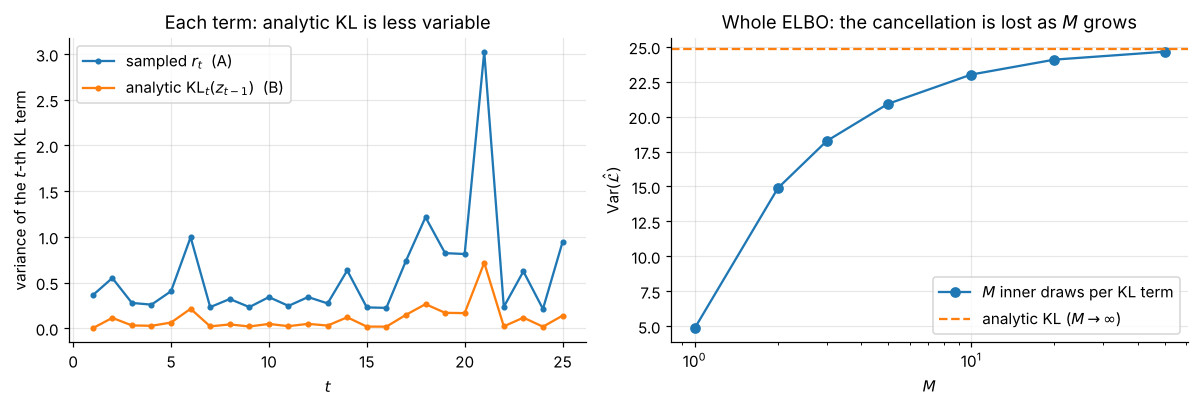

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, T + 1), r_samp.var(0), "o-", ms=3, label=r"sampled $r_t$  (A)")
axes[0].plot(np.arange(1, T + 1), kl_an.var(0), "o-", ms=3, label=r"analytic KL$_t(z_{t-1})$  (B)")
axes[0].set_xlabel("$t$"); axes[0].set_ylabel("variance of the $t$-th KL term")
axes[0].set_title("Each term: analytic KL is less variable"); axes[0].legend()

Ms = np.array([1, 2, 3, 5, 10, 20, 50])
var_M = [elbo_A(z_s[:50_000], s0, delta0).var()] + [elbo_M(z_s[:50_000], M, s0, delta0, rng).var() for M in Ms[1:]]
axes[1].semilogx(Ms, var_M, "o-", label="$M$ inner draws per KL term")
axes[1].axhline(results["B  (analytic KL)"].var(), color="C1", ls="--", label=r"analytic KL ($M\to\infty$)")
axes[1].set_xlabel("$M$"); axes[1].set_ylabel(r"Var$(\hat{\mathcal{L}})$")
axes[1].set_title("Whole ELBO: the cancellation is lost as $M$ grows"); axes[1].legend()
plt.tight_layout()
plt.show()

**Lesson.** Rao–Blackwellisation guarantees lower variance for the quantity it is applied to. It guarantees nothing
for a *sum* whose other terms were correlated with it. Whether it helps the whole estimator depends on the
covariances, and here on how close the encoder is to the true posterior. Section 6 measures this for gradients too.

## 6. Gradients: what "factorising the KL" buys during training

The paper's own justification is about **gradients**: estimating the KL term by sampling gives high-variance
gradients. With the reparameterisation trick, $z_t = \alpha_t z_{t-1} + \beta_t + \gamma_t\varepsilon_t$, each
estimator above is a differentiable function of the encoder parameters for fixed noise $\varepsilon$. Its
derivative is an unbiased estimate of $\nabla\mathcal{L}$.

We differentiate with respect to the two perturbation parameters $s$ (scale of the stds) and $\delta$ (shift of
the means). To stay dependency-free we use central finite differences with **common random numbers**, i.e. the
same $\varepsilon$ on both sides. For small $h$ this is exactly the pathwise, reparameterised gradient. The
exact gradient comes from differentiating the closed-form ELBO.

In [8]:
def pathwise_grad(estimator, theta, n, rng, h=1e-5):
    """Reparameterised gradient samples of an ELBO estimator w.r.t. (s, delta), one per trajectory."""
    s, d = theta
    eps = rng.standard_normal((n, T))
    grads = []
    for ds, dd in ((h, 0.0), (0.0, h)):
        zp, _ = sample_trajectories(n, s + ds, d + dd, rng, eps)
        zm, _ = sample_trajectories(n, s - ds, d - dd, rng, eps)
        grads.append((estimator(zp, s + ds, d + dd) - estimator(zm, s - ds, d - dd)) / (2 * h))
    return np.stack(grads, axis=1)


h = 1e-5
g_exact = np.array([(exact_elbo(s0 + h, delta0) - exact_elbo(s0 - h, delta0)) / (2 * h),
                    (exact_elbo(s0, delta0 + h) - exact_elbo(s0, delta0 - h)) / (2 * h)])

n = 100_000
gA = pathwise_grad(elbo_A, (s0, delta0), n, rng)
gB = pathwise_grad(elbo_B, (s0, delta0), n, rng)
print(f"{'':<26}{'dL/ds':>18}{'dL/d delta':>18}")
print(f"{'exact':<26}{g_exact[0]:>18.3f}{g_exact[1]:>18.3f}")
for name, g in (("A  sampled KL  (mean)", gA), ("B  analytic KL (mean)", gB)):
    print(f"{name:<26}{g[:, 0].mean():>18.3f}{g[:, 1].mean():>18.3f}")
for name, g in (("A  sampled KL  (std)", gA), ("B  analytic KL (std)", gB)):
    print(f"{name:<26}{g[:, 0].std():>18.3f}{g[:, 1].std():>18.3f}")

                                       dL/ds        dL/d delta
exact                                 -8.746           -24.285
A  sampled KL  (mean)                 -8.766           -24.192
B  analytic KL (mean)                 -8.743           -24.281
A  sampled KL  (std)                   9.728            18.069
B  analytic KL (std)                   7.587            16.759


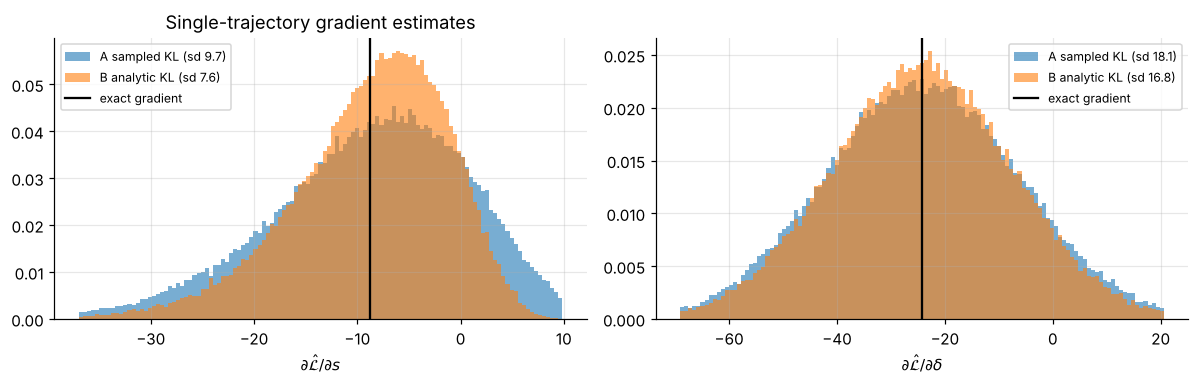

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, j, lab in zip(axes, (0, 1), (r"$\partial\hat{\mathcal{L}}/\partial s$", r"$\partial\hat{\mathcal{L}}/\partial \delta$")):
    lo, hi = np.percentile(np.concatenate([gA[:, j], gB[:, j]]), [0.5, 99.5])
    bins = np.linspace(lo, hi, 120)
    ax.hist(gA[:, j], bins=bins, density=True, alpha=0.6, label=f"A sampled KL (sd {gA[:, j].std():.1f})")
    ax.hist(gB[:, j], bins=bins, density=True, alpha=0.6, label=f"B analytic KL (sd {gB[:, j].std():.1f})")
    ax.axvline(g_exact[j], color="k", lw=1.5, label="exact gradient")
    ax.set_xlabel(lab); ax.legend(fontsize=8)
axes[0].set_title("Single-trajectory gradient estimates")
plt.tight_layout()
plt.show()

Both gradient estimators are unbiased, and here the analytic-KL gradients are less noisy, though only moderately.

How do values and gradients compare as the encoder moves from very good to poor? The rows below range from the exact
posterior ($s=\delta=0$), through increasingly wide and shifted encoders, to two encoders that are too *narrow*
($s<0$), a typical failure mode.

In [10]:
print(f"{'s':>6}{'delta':>7}{'gap':>8} | {'Var(value)':^19} | {'sd(dL/ds)':^15} | {'sd(dL/d delta)':^15}")
print(f"{'':>21} | {'A':>8}{'B':>10} | {'A':>7}{'B':>8} | {'A':>7}{'B':>8}")
for s, d in [(0.0, 0.0), (0.05, 0.03), (0.15, 0.1), (0.3, 0.2), (0.6, 0.5), (1.0, 1.0), (-0.3, 0.2), (-0.6, 0.0)]:
    zz, _ = sample_trajectories(100_000, s, d, rng)
    vA, vB = elbo_A(zz, s, d).var(), elbo_B(zz, s, d).var()
    gA_, gB_ = pathwise_grad(elbo_A, (s, d), 50_000, rng), pathwise_grad(elbo_B, (s, d), 50_000, rng)
    print(f"{s:>6}{d:>7}{max(log_px - exact_elbo(s, d), 0.0):>8.2f} | {vA:>8.2f}{vB:>10.2f} | "
          f"{gA_[:, 0].std():>7.2f}{gB_[:, 0].std():>8.2f} | {gA_[:, 1].std():>7.2f}{gB_[:, 1].std():>8.2f}")

     s  delta     gap |     Var(value)      |    sd(dL/ds)    | sd(dL/d delta) 
                      |        A         B |       A       B |       A       B


   0.0    0.0    0.00 |     0.00     11.20 |    7.11    5.40 |   15.68   14.49


  0.05   0.03    0.17 |     0.38     14.13 |    7.82    6.00 |   16.38   15.20


  0.15    0.1    1.84 |     4.83     24.71 |    9.63    7.51 |   18.00   16.66


   0.3    0.2    7.63 |    26.06     55.16 |   13.57   10.64 |   20.99   19.43


   0.6    0.5   44.36 |   267.45    304.16 |   27.41   22.34 |   28.49   26.23


   1.0    1.0  176.29 |  2309.66   2124.59 |   67.34   55.81 |   42.56   39.37


  -0.3    0.2    6.72 |     7.80     12.47 |    4.51    4.22 |   11.57   10.64


  -0.6    0.0    6.26 |     6.17      2.13 |    2.14    1.92 |    8.56    7.89


Reading the table:

* **Gradients:** for every encoder tried, the analytic KL (B) gives lower-variance gradients. The improvement is
  real but moderate in this model, roughly 5–25 % in standard deviation. This is the direction the paper reports.
* **Values:** for a good encoder, the fully sampled estimator (A) is *far* less variable, because of the
  cancellation explained in section 5, and it is exactly constant at the posterior. For a poor or too-narrow
  encoder, (B) can win.
* **Why (A)'s gradient is not zero-variance at the posterior, although its value is.** The reparameterised
  gradient of $\log q(\mathbf{z}\mid\mathbf{x})$ contains a term $\partial_\theta \log q(\mathbf{z};\theta)$ taken with
  $\mathbf{z}$ held fixed. That term has mean zero but nonzero variance. Dropping it gives an estimator whose
  variance vanishes at the posterior; see *sticking the landing* (Roeder, Wu & Duvenaud, 2017).

**Why the factorisation matters regardless.** Without it, the KL term would be
$\mathrm{KL}\big(q(\mathbf{z}\mid\mathbf{x})\,\|\,p(\mathbf{z})\big)$ between two $T$-dimensional distributions. That
KL has no closed form when the transitions are neural networks, so it could only be sampled. After the
factorisation, **every remaining KL is between two univariate (or diagonal) Gaussians given $z_{t-1}$**, which is
closed form whatever networks produce their means and variances. The factorisation is what makes analytic KLs
*possible*. Section 5 shows that whether they *help* depends on the quantity and on the encoder. For training
gradients, they helped here in every case.

## 7. How this repository's code implements it

`DKF_Base.forward` in `Models/dkf_models.py` runs exactly the ancestral sampler of section 3, one trajectory per
sequence in the batch:

```python
for t in range(0, seq_len):
    combined = self.combiner(sampled_z_t, [q_b_rnn_out[t,:,:]])   # z_{t-1} and backward RNN state for x_{t:T}
    mu, logvar = self.encoder(combined)                           # q(z_t | z_{t-1}, x)
    sampled_z_t = self.sampler(mu, logvar)                        # reparameterised draw of z_t
...
z_t_minus_1 = torch.cat([z_0, self.sampled_z[:-1, :,:]], 0)
self.z_transition_mean, self.z_transition_logvar = self.p_z(z_t_minus_1)   # p(z_t | sampled z_{t-1})
```

`loss_function` in `Utils/loss_fcts.py` then computes, per sequence and up to the $1/T$ normalisation and the
batch mean,

$$
\underbrace{\sum_{t,d}\Big[\frac{(x_{t,d}-\hat x_{t,d})^2}{\hat\sigma^2_{t,d}} + \log\hat\sigma^2_{t,d}\Big]}_{\text{weighted MSE term}}
\;+\;\beta\,\underbrace{\sum_{t,d}\Big[\log\sigma^2_{p} - \log\sigma^2_{q} + \tfrac{\sigma^2_q + (\mu_p-\mu_q)^2}{\sigma^2_p}\Big]}_{\text{KL term}} .
$$

Compare with the Gaussian formulas:
* $-2\log\mathcal{N}(x;\hat x,\hat\sigma^2) = \frac{(x-\hat x)^2}{\hat\sigma^2} + \log\hat\sigma^2 + \log 2\pi$, so the
  first sum is $-2\sum_t\log p(x_t\mid z_t)$ minus a constant.
* $2\,\mathrm{KL} = \log\sigma_p^2 - \log\sigma_q^2 + \frac{\sigma_q^2 + (\mu_q-\mu_p)^2}{\sigma_p^2} - 1$, so the
  second sum is $2\sum_t \mathrm{KL}_t$ plus a constant.

Hence, with $\beta = 1$,

$$
\text{loss} = -\frac{2}{T}\,\hat{\mathcal{L}}_B \;+\; \text{const},
$$

**so the training loss is exactly estimator (B): one ancestral trajectory, analytic conditional KLs.** The constants
($d_x\log 2\pi$ and $d_z$ per time step) do not affect gradients. The KL at $t = 1$ is taken against
$p(z_1\mid z_0)$ with the learnable $z_0$, which is the first term of the factorised KL. With $\beta\ne1$ the
objective becomes a $\beta$-weighted bound, and with `loss_type='mse'` the decoder variance is dropped, so the
reconstruction term is no longer a log-likelihood.

A quick numerical check of the KL identity on random values:

In [11]:
mu_q, lv_q, mu_p, lv_p = rng.normal(size=(4, 5))
code_kl = (lv_p - lv_q + (np.exp(lv_q) + (mu_p - mu_q) ** 2) / np.exp(lv_p))       # as in loss_fcts.py
true_kl = 0.5 * (lv_p - lv_q) + (np.exp(lv_q) + (mu_q - mu_p) ** 2) / (2 * np.exp(lv_p)) - 0.5
print("code_kl - 2*KL =", (code_kl - 2 * true_kl).round(12), "(the constant 1 per dimension)")

code_kl - 2*KL = [1. 1. 1. 1. 1.] (the constant 1 per dimension)


## 8. Where nesting really appears: $\log p(\mathbf{x})$ and IWAE

The quantity the ELBO bounds is

$$
\log p(\mathbf{x}) = \log \mathbb{E}_{q(\mathbf{z}\mid\mathbf{x})}\big[w(\mathbf{z})\big],
\qquad w(\mathbf{z}) = \frac{p(\mathbf{x},\mathbf{z})}{q(\mathbf{z}\mid\mathbf{x})}.
$$

Here a $\log$ is applied to an expectation, which is the nested situation. Estimating it with $K$ trajectories,

$$
\hat{\mathcal{L}}_K = \log\frac1K\sum_{k=1}^K w(\mathbf{z}^{(k)}),\qquad \mathbf{z}^{(k)}\sim q(\mathbf{z}\mid\mathbf{x}),
$$

gives the importance-weighted (IWAE) bound $\mathcal{L}_K = \mathbb{E}[\hat{\mathcal{L}}_K]$. Everything from
Part 2 of the companion repository applies:

* $\mathcal{L}_K \le \log p(\mathbf{x})$ for every $K$ (Jensen), and the bias is negative.
* $\mathcal{L}_1 = \mathcal{L}$, the ELBO. **The ELBO is the $K = 1$ member of a nested estimator.** That is why a
  single sample is enough for the ELBO but not for $\log p(\mathbf{x})$.
* $\mathcal{L}_K$ increases with $K$ (Burda et al., 2016), and the bias behaves like
  $-\dfrac{\rho}{2K}$ for large $K$, where $\rho = \mathrm{Var}_q\big(w/p(\mathbf{x})\big)$ is the relative variance
  of the weights.

In this Gaussian model $\rho$ has a closed form, since $\mathbb{E}_q\big[(w/p(\mathbf{x}))^2\big] = \int p(\mathbf{z}\mid\mathbf{x})^2/q(\mathbf{z})\,d\mathbf{z}$
is a Gaussian integral. So we can compare the measured bias with the prediction.

In [12]:
def weight_relative_variance(s, delta):
    """rho = E_q[(w / p(x))^2] - 1 = int p(z|x)^2 / q(z) dz - 1, for Gaussian p(z|x) and q."""
    m, S = q_joint(*encoder(s, delta))
    S_inv, P_inv = np.linalg.inv(S), np.linalg.inv(Sigma_post)
    Lam = 2 * P_inv - S_inv
    if np.linalg.eigvalsh(Lam).min() <= 0:
        return np.inf                                   # q too narrow: weights have infinite variance
    eta = 2 * P_inv @ mu_post - S_inv @ m
    kappa = (-T / 2 * LOG2PI - np.linalg.slogdet(Sigma_post)[1] + 0.5 * np.linalg.slogdet(S)[1]
             - mu_post @ P_inv @ mu_post + 0.5 * m @ S_inv @ m)
    log_int = kappa + 0.5 * eta @ np.linalg.solve(Lam, eta) + T / 2 * LOG2PI - 0.5 * np.linalg.slogdet(Lam)[1]
    return np.exp(log_int) - 1


rho = weight_relative_variance(s0, delta0)
print(f"relative variance of the weights rho = {rho:.3f}")


def log_mean_exp(v, axis=-1):
    v_max = v.max(axis=axis, keepdims=True)
    return np.squeeze(v_max, axis) + np.log(np.mean(np.exp(v - v_max), axis=axis))


Ks = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
iwae_mean, iwae_se = [], []
for K in Ks:
    reps = max(4_000_000 // K, 4000)
    vals = np.empty(reps)
    chunk = max(1, 400_000 // K)                        # trajectories per batch: chunk * K <= 400k
    for c in range(0, reps, chunk):
        nb = min(chunk, reps - c)
        z_k, _ = sample_trajectories(nb * K, s0, delta0, rng)
        vals[c:c + nb] = log_mean_exp(elbo_A(z_k, s0, delta0).reshape(nb, K))
    iwae_mean.append(vals.mean()); iwae_se.append(vals.std() / np.sqrt(reps))
iwae_mean, iwae_se = np.array(iwae_mean), np.array(iwae_se)
for K, mval, se in zip(Ks, iwae_mean, iwae_se):
    print(f"K = {K:>4}:  L_K = {mval:.4f} ± {1.96 * se:.4f}   bias = {mval - log_px:+.4f}   -rho/(2K) = {-rho / (2 * K):+.4f}")

relative variance of the weights rho = 8.954


K =    1:  L_K = -31.9933 ± 0.0021   bias = -1.8372   -rho/(2K) = -4.4771
K =    2:  L_K = -31.2607 ± 0.0022   bias = -1.1047   -rho/(2K) = -2.2385
K =    5:  L_K = -30.7061 ± 0.0023   bias = -0.5501   -rho/(2K) = -0.8954
K =   10:  L_K = -30.4718 ± 0.0025   bias = -0.3158   -rho/(2K) = -0.4477
K =   20:  L_K = -30.3328 ± 0.0026   bias = -0.1768   -rho/(2K) = -0.2239
K =   50:  L_K = -30.2339 ± 0.0027   bias = -0.0778   -rho/(2K) = -0.0895
K =  100:  L_K = -30.1966 ± 0.0028   bias = -0.0406   -rho/(2K) = -0.0448
K =  200:  L_K = -30.1773 ± 0.0029   bias = -0.0213   -rho/(2K) = -0.0224
K =  500:  L_K = -30.1665 ± 0.0029   bias = -0.0105   -rho/(2K) = -0.0090
K = 1000:  L_K = -30.1581 ± 0.0029   bias = -0.0020   -rho/(2K) = -0.0045


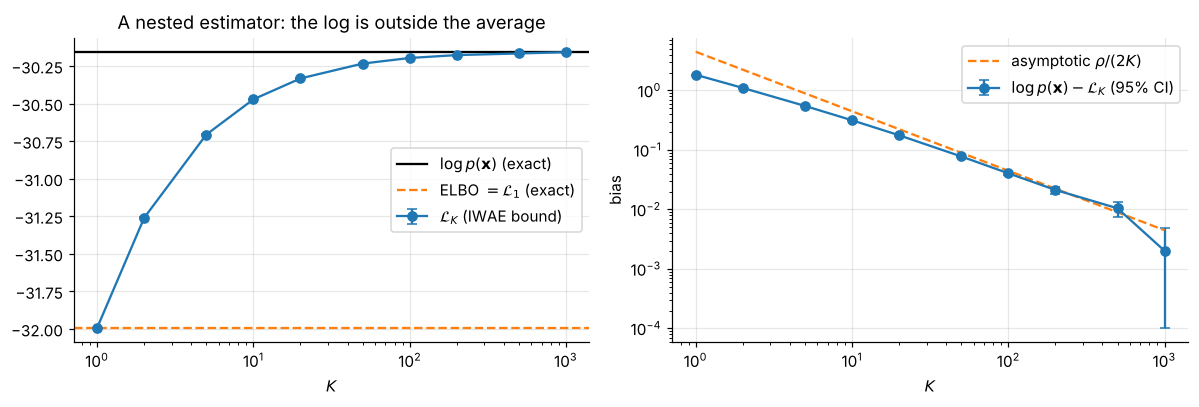

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].errorbar(Ks, iwae_mean, yerr=1.96 * iwae_se, fmt="o-", capsize=3, label=r"$\mathcal{L}_K$ (IWAE bound)")
axes[0].axhline(log_px, color="k", lw=1.5, label=r"$\log p(\mathbf{x})$ (exact)")
axes[0].axhline(elbo_true, color="C1", ls="--", label=r"ELBO $=\mathcal{L}_1$ (exact)")
axes[0].set_xscale("log"); axes[0].set_xlabel("$K$"); axes[0].legend()
axes[0].set_title("A nested estimator: the log is outside the average")
bias_K, err_K = log_px - iwae_mean, 1.96 * iwae_se
axes[1].errorbar(Ks, bias_K, yerr=[np.minimum(err_K, 0.95 * bias_K), err_K], fmt="o-", capsize=3,
                 label=r"$\log p(\mathbf{x}) - \mathcal{L}_K$ (95% CI)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].loglog(Ks, rho / (2 * Ks), "--", label=r"asymptotic $\rho/(2K)$")
axes[1].set_xlabel("$K$"); axes[1].set_ylabel("bias"); axes[1].legend()
plt.tight_layout()
plt.show()

As in Part 2 of the companion repository, there is a pre-asymptotic regime at small $K$, followed by the $1/K$
law once $K \gg \rho$. At $K \ge 500$ the remaining bias is comparable to the Monte Carlo error, as the
confidence intervals show.

**A warning specific to sequence models.** The relative variance $\rho$ of the weights is a property of the
*whole trajectory*. Small per-step mismatches between $q$ and the posterior multiply over time, so $\rho$ grows
roughly exponentially with $T$ and with the quality gap of the encoder:

In [14]:
print(f"{'s':>6}{'delta':>8}{'KL(q||post)':>14}{'rho':>14}")
for s, d in [(0.05, 0.03), (0.1, 0.05), (0.15, 0.1), (0.2, 0.1), (0.25, 0.15), (0.3, 0.2)]:
    print(f"{s:>6}{d:>8}{log_px - exact_elbo(s, d):>14.3f}{weight_relative_variance(s, d):>14.1f}")

     s   delta   KL(q||post)           rho
  0.05    0.03         0.174           0.3
   0.1    0.05         0.571           1.3
  0.15     0.1         1.837           9.0
   0.2     0.1         2.362          13.3
  0.25    0.15         4.591          87.3
   0.3     0.2         7.633         676.8


The $1/K$ regime needs $K \gg \rho$. For long sequences and an imperfect encoder, importance-weighted estimates of
$\log p(\mathbf{x})$ can therefore stay far below the true value for any affordable $K$. This is worth remembering when
reading or reporting test log-likelihoods of sequence models.

## 9. Summary

| | ELBO terms of the DKF | $\log p(\mathbf{x})$ / IWAE |
|---|---|---|
| Form | $\mathbb{E}_{q(z_{t-1})}\big[\mathrm{KL}_t(z_{t-1})\big]$ and $\mathbb{E}_{q(z_t)}\big[\log p(x_t\mid z_t)\big]$ | $\log\mathbb{E}_{q(\mathbf{z})}[w(\mathbf{z})]$ |
| Nonlinearity outside the inner expectation? | No | Yes ($\log$) |
| Type | Hierarchical | Nested |
| Samples needed for an unbiased estimate | One ancestral trajectory | None suffice: bias $\approx -\rho/(2K)$ |
| Marginals $q(z_t\mid\mathbf{x})$ needed? | No: ancestral sampling | No |
| Role of the analytic KL | Rao–Blackwellisation of each KL term; lower-variance gradients here, but not always a lower-variance ELBO value | — |

Answers to the three questions from the introduction:

1. The factorised KL is the chain rule for KL divergence. Each log-ratio term only involves $(z_{t-1}, z_t)$, so its
   expectation splits into an outer expectation over $q(z_{t-1}\mid\mathbf{x})$ and an inner one, which is the KL.
2. The expectation over the intractable marginal $q(z_{t-1}\mid\mathbf{x})$ is computed by **ancestral sampling**:
   one trajectory gives exact samples of all marginals at once. Since every term is linear in its inner expectation,
   this is hierarchical Monte Carlo, unbiased with a single trajectory. It is *not* nested Monte Carlo.
3. Computing the KL in closed form at the sampled $z_{t-1}$ integrates out $z_t$ exactly. That is
   Rao–Blackwellisation, and it reduces the variance of *each KL term*. For the whole ELBO, the sampled version can
   be less noisy because its terms cancel, especially near the optimum. For the gradients, the analytic KL was the
   better choice for every encoder tried here, though by a moderate margin. The factorisation is what makes the
   closed form available at all. `Utils/loss_fcts.py` implements exactly this estimator, up to constants.

### References
* R. G. Krishnan, U. Shalit, D. Sontag. *Deep Kalman Filters.* arXiv:1511.05121, 2015.
* R. G. Krishnan, U. Shalit, D. Sontag. *Structured Inference Networks for Nonlinear State Space Models.* AAAI 2017.
* Y. Burda, R. Grosse, R. Salakhutdinov. *Importance Weighted Autoencoders.* ICLR 2016.
* G. Roeder, Y. Wu, D. Duvenaud. *Sticking the Landing: Simple, Lower-Variance Gradient Estimators for Variational Inference.* NeurIPS 2017.
* T. Rainforth, R. Cornish, H. Yang, A. Warrington, F. Wood. *On Nesting Monte Carlo Estimators.* ICML 2018.
* Companion notebooks: [Nested-Monte-Carlo-sampling](https://github.com/CL-BZH/Nested-Monte-Carlo-sampling).